
# 03. Exploratory Data Analysis — Australian Legal Corpus

## Project: LexiAssist
### AI-Powered Legal Research Assistant

## Objective

This notebook performs Exploratory Data Analysis (EDA)
on the cleaned Australian Legal Corpus.

The goal is to understand the characteristics,
distributions, and patterns within the legal documents
before implementing the retrieval system.

## EDA Tasks

1. Dataset overview and descriptive statistics
2. Legal document type distribution
3. Jurisdiction distribution
4. Source distribution
5. Publication date and year analysis
6. Document length analysis
7. Missing metadata analysis
8. Relationships between categorical attributes
9. Key findings and implications for RAG

Dataset: Open Australian Legal Corpus
Sample Size: 1,000 documents


## Environment Setup and Dataset Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
from google.colab import files

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    encoding="utf-8-sig",
    low_memory=False
)
df["date"] = pd.to_datetime(
    df["date"], errors="coerce"
)
df["when_scraped"] = pd.to_datetime(
    df["when_scraped"],
    errors="coerce",
    utc=True
)
print("Loaded:", filename)
print("Dataset shape:", df.shape)
display(df.head())

Saving australian_legal_corpus_cleaned.csv to australian_legal_corpus_cleaned.csv
Loaded: australian_legal_corpus_cleaned.csv
Dataset shape: (1000, 14)


,version_id,type,jurisdiction,source,mime,date,citation,url,when_scraped,text,date_missing,word_count,char_count,length_outlier
0,tasmanian_legislation:2000-08-02/sr-2000-118,secondary_legislation,tasmania,tasmanian_legislation,text/html,2000-08-02,Proclamation under the National Parks and Wild...,https://www.legislation.tas.gov.au/view/whole/...,2024-09-13 12:47:55.638633+00:00,Proclamation under the National Parks and Wild...,False,261,1560,False
1,nsw_caselaw:5ae13d1de4b074a7c6e1e9a9,decision,new_south_wales,nsw_caselaw,text/html,2018-04-27,R v Oncu; R v Dogan; R v Unver; R v Bassi-Anst...,https://www.caselaw.nsw.gov.au/decision/5ae13d...,2024-09-13 13:44:14.576816+00:00,District Court\nNew South Wales\n\nMedium Neut...,False,5961,34311,False
2,nsw_caselaw:59000bb2e4b0e71e17f5902d,decision,new_south_wales,nsw_caselaw,text/html,2017-04-27,CPU v Children’s Guardian [2017] NSWCATAD 131,https://www.caselaw.nsw.gov.au/decision/59000b...,2024-09-13 13:29:05.309922+00:00,Civil and Administrative Tribunal\nNew South W...,False,7593,44380,False
3,tasmanian_legislation:2020-12-02/sr-2020-081,secondary_legislation,tasmania,tasmanian_legislation,text/html,2020-12-02,Fisheries (Processing and Handling) Amendment ...,https://www.legislation.tas.gov.au/view/whole/...,2024-09-13 13:08:39.283882+00:00,Fisheries (Processing and Handling) Amendment ...,False,144,916,False
4,tasmanian_legislation:2000-12-27/sr-2000-244,secondary_legislation,tasmania,tasmanian_legislation,text/html,2000-12-27,Proclamation under the National Parks and Wild...,https://www.legislation.tas.gov.au/view/whole/...,2024-09-13 13:08:12.380116+00:00,Proclamation under the National Parks and Wild...,False,257,1524,False


## 1. Dataset Overview

In [ ]:
print("DATASET INFORMATION")
df.info()
print("\nMISSING VALUES")
display(df.isna().sum().to_frame("Missing Count"))
print("\nDOCUMENT TYPES")
display(df["type"].value_counts())
print("\nJURISDICTIONS")
display(df["jurisdiction"].value_counts())
print("\nNUMERICAL SUMMARY")
display(df[["word_count", "char_count"]].describe())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype              
---  ------          --------------  -----              
 0   version_id      1000 non-null   object             
 1   type            1000 non-null   object             
 2   jurisdiction    1000 non-null   object             
 3   source          1000 non-null   object             
 4   mime            1000 non-null   object             
 5   date            893 non-null    datetime64[ns]     
 6   citation        1000 non-null   object             
 7   url             1000 non-null   object             
 8   when_scraped    1000 non-null   datetime64[ns, UTC]
 9   text            1000 non-null   object             
 10  date_missing    1000 non-null   bool               
 11  word_count      1000 non-null   int64              
 12  char_count      1000 non-null   int64              
 13  length_outlier

,Missing Count
version_id,0
type,0
jurisdiction,0
source,0
mime,0
date,107
citation,0
url,0
when_scraped,0
text,0



DOCUMENT TYPES


,count
type,
decision,616
secondary_legislation,180
primary_legislation,169
bill,35



JURISDICTIONS


,count
jurisdiction,
new_south_wales,367
commonwealth,333
tasmania,114
western_australia,74
queensland,61
south_australia,51



NUMERICAL SUMMARY


,word_count,char_count
count,1000.000000,1000.000000
mean,6370.850000,37752.831000
std,8846.274677,52520.279291
min,25.000000,158.000000
25%,1335.500000,8019.500000
50%,3526.500000,20648.500000
75%,7649.000000,45221.750000
max,91018.000000,531187.000000



## 1. Dataset Overview

The cleaned dataset consists of 1,000 Australian legal
documents with metadata and full legal text.

The dataset includes categorical attributes such as
document type, jurisdiction, and source, along with
publication dates and document-length measurements.

Additional attributes generated during cleaning include:

- `date_missing`: Identifies missing publication dates.
- `word_count`: Number of words in each document.
- `char_count`: Number of characters in each document.
- `length_outlier`: Flags unusual document lengths.

These attributes support further analysis of the
corpus and help identify potential retrieval challenges.


## 2. Legal Document Type Distribution

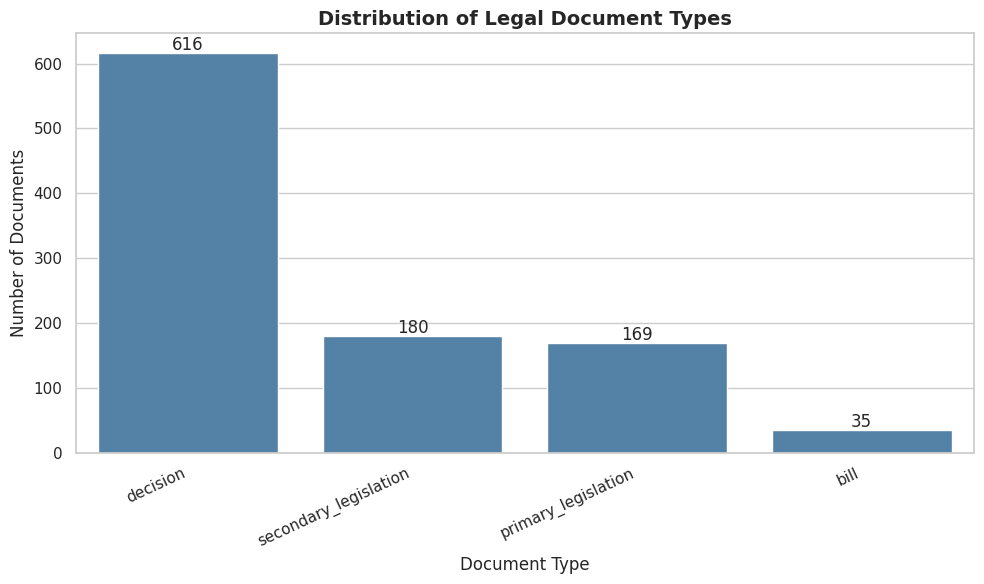


Document Type Percentages:


,Percentage
type,
decision,61.6
secondary_legislation,18.0
primary_legislation,16.9
bill,3.5


In [ ]:
type_counts = df["type"].value_counts()
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=type_counts.index,
    y=type_counts.values,
    color="steelblue"
)
plt.title(
    "Distribution of Legal Document Types",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Document Type")
plt.ylabel("Number of Documents")
plt.xticks(rotation=25, ha="right")
for i, count in enumerate(type_counts.values):
    ax.text(
        i, count + 5,
        str(count),
        ha="center"
    )

plt.tight_layout()
plt.show()
print("\nDocument Type Percentages:")
display(
    df["type"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)



## 2. Legal Document Type Distribution

### Visualization
A bar chart was generated to examine the distribution
of legal document types within the corpus.

### Key Findings

The initial dataset audit identified decisions as
the largest document category, containing 616 of
the 1,000 sampled documents (61.6%).

This indicates an imbalance in the representation
of different types of Australian legal material.

### Implications for LexiAssist

Unequal document representation may influence
retrieval results because some categories have
more indexed content than others.

This imbalance should be considered during retrieval
evaluation, particularly when comparing performance
across legal document types.


## 3. Jurisdiction Distribution

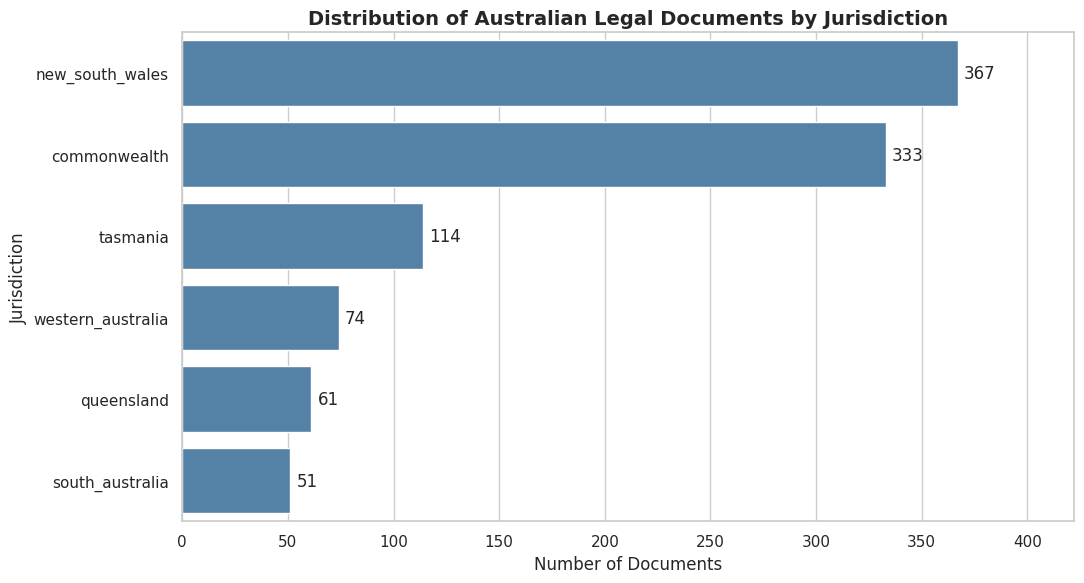

Jurisdiction Percentages:


,Percentage
jurisdiction,
new_south_wales,36.7
commonwealth,33.3
tasmania,11.4
western_australia,7.4
queensland,6.1
south_australia,5.1


In [ ]:
jurisdiction_counts = df["jurisdiction"].value_counts()
plt.figure(figsize=(11, 6))
ax = sns.barplot(
    x=jurisdiction_counts.values,
    y=jurisdiction_counts.index,
    color="steelblue"
)
plt.title(
    "Distribution of Australian Legal Documents by Jurisdiction",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Number of Documents")
plt.ylabel("Jurisdiction")
for i, count in enumerate(jurisdiction_counts.values):
    ax.text(
        count + 3,
        i,
        str(count),
        va="center"
    )
plt.xlim(0, jurisdiction_counts.max() * 1.15)
plt.tight_layout()
plt.show()
print("Jurisdiction Percentages:")
display(
    df["jurisdiction"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)



## 3. Jurisdiction Distribution

### Visualization

A horizontal bar chart was created to examine the
distribution of legal documents across Australian
jurisdictions.

### Key Findings

New South Wales has the highest representation with
367 documents (36.7%), followed by the Commonwealth
with 333 documents (33.3%).

Together, these jurisdictions account for 70% of
the sampled corpus.

Tasmania contributes 11.4%, while Western Australia,
Queensland, and South Australia have comparatively
smaller representations.

### Implications for LexiAssist

The uneven distribution of documents may influence
retrieval coverage across jurisdictions.

Jurisdictions with fewer documents may have limited
representation for certain legal topics.

During model evaluation, retrieval performance should
be assessed across different jurisdictions to identify
potential coverage gaps.

These findings describe the sampled corpus and should
not be interpreted as the distribution of all
Australian legal documents.


## 4. Legal Data Source Distribution

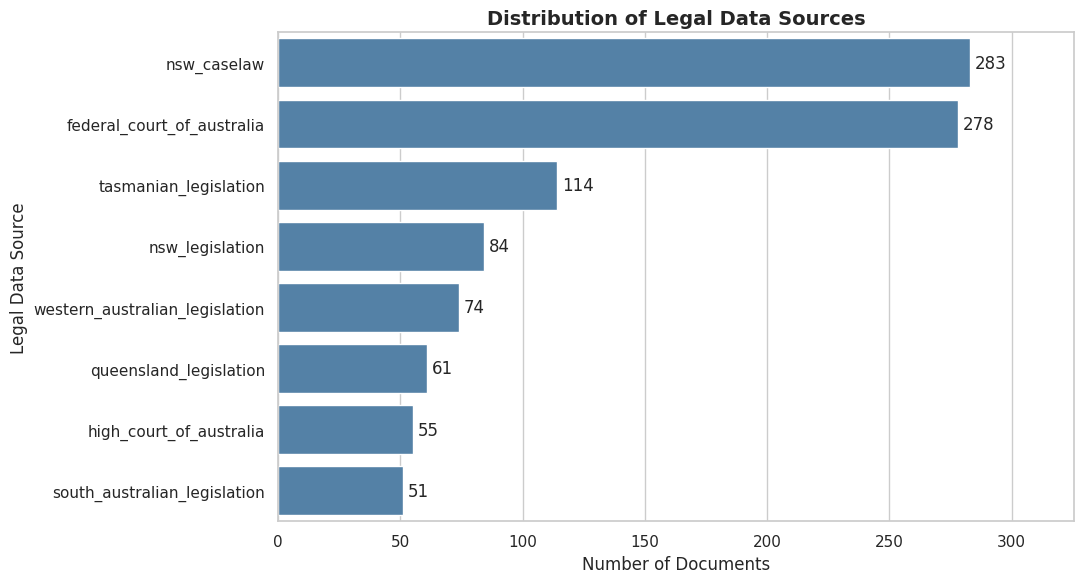

Source Distribution:


,Percentage
source,
nsw_caselaw,28.3
federal_court_of_australia,27.8
tasmanian_legislation,11.4
nsw_legislation,8.4
western_australian_legislation,7.4
queensland_legislation,6.1
high_court_of_australia,5.5
south_australian_legislation,5.1


In [ ]:
source_counts = df["source"].value_counts()
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=source_counts.values,
    y=source_counts.index,
    color="steelblue"
)

plt.title(
    "Distribution of Legal Data Sources",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Number of Documents")
plt.ylabel("Legal Data Source")

for i, count in enumerate(source_counts.values):
    ax.text(count + 2, i, str(count), va="center")

plt.xlim(0, source_counts.max() * 1.15)
plt.tight_layout()
plt.show()

print("Source Distribution:")
display(
    df["source"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)



## 4. Legal Data Source Distribution

### Visualization

A horizontal bar chart was generated to examine
the distribution of legal documents across
different data sources.

### Key Findings

The corpus contains documents from eight legal data sources.

NSW Caselaw contributes the largest number of documents
(283, 28.3%), closely followed by the Federal Court
of Australia (278, 27.8%).

Together, these sources account for 56.1% of the sample.

South Australian Legislation is the least represented
source, contributing 51 documents (5.1%).

This indicates uneven source representation within
the sampled legal corpus.

### Implications for LexiAssist

Unequal source representation may affect retrieval
coverage and the diversity of retrieved documents.

Sources with fewer documents may have limited
representation for certain legal topics.

These differences should be considered during
retrieval evaluation.





## 5. Publication Year Analysis

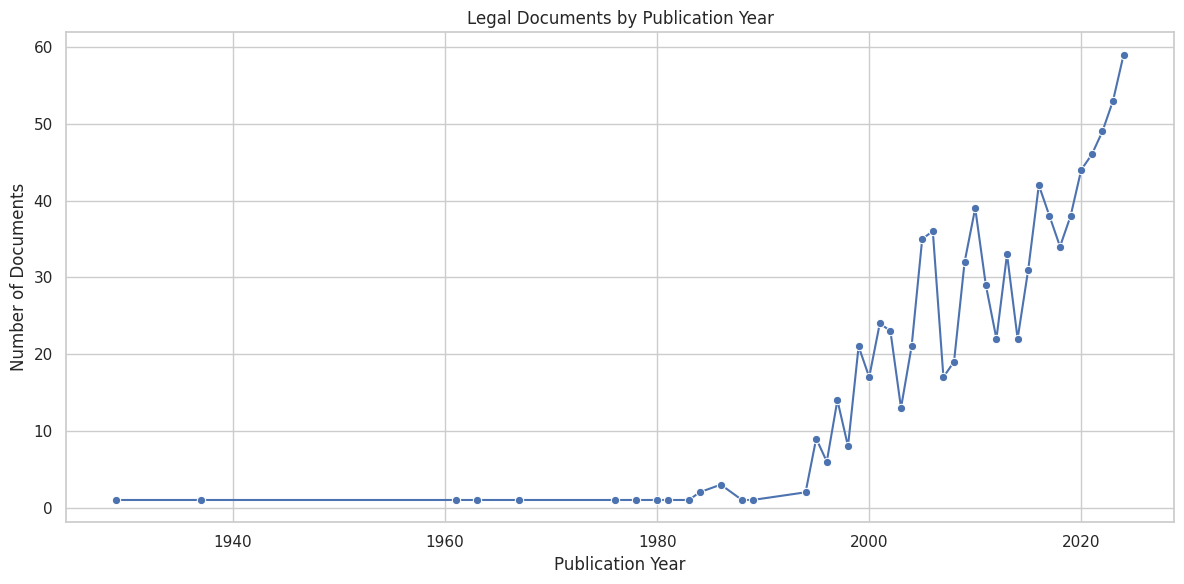

Documents with missing publication year: 107

Publication year statistics:


,publication_year
count,893.000000
mean,2012.236282
std,9.946220
min,1929.000000
25%,2006.000000
50%,2014.000000
75%,2020.000000
max,2024.000000



Most represented years:


,count
publication_year,
2024.0,59
2023.0,53
2022.0,49
2021.0,46
2020.0,44
2016.0,42
2010.0,39
2019.0,38
2017.0,38


In [ ]:
df["publication_year"] = df["date"].dt.year
year_counts = (
    df["publication_year"]
    .value_counts()
    .sort_index()
)
plt.figure(figsize=(12, 6))
sns.lineplot(
    x=year_counts.index,
    y=year_counts.values,
    marker="o"
)
plt.title("Legal Documents by Publication Year")
plt.xlabel("Publication Year")
plt.ylabel("Number of Documents")
plt.tight_layout()
plt.show()
print("Documents with missing publication year:",df["publication_year"].isna().sum())
print("\nPublication year statistics:")
display(df["publication_year"].describe())
print("\nMost represented years:")
display(
    df["publication_year"]
    .value_counts()
    .head(10)
)


## 5. Publication Year Analysis

### Visualization

A line chart was generated to examine the distribution
of legal documents by publication year.

### Key Findings

The dataset contains 893 documents with valid
publication dates, while 107 documents (10.7%)
have missing dates.

The recorded publication years range from 1929
to 2024, with a median year of 2014.

The most represented year is 2024, containing
59 documents.

### Implications for LexiAssist

The corpus contains legal materials from different
historical periods.

Older legal documents may remain relevant for legal
research, but some legislation may have been amended
or repealed.

LexiAssist should preserve publication dates and
source information to help users assess the temporal
relevance of retrieved documents.

The corpus is a static sample and does not guarantee
coverage of current Australian law.


## 6. Document Length Analysis

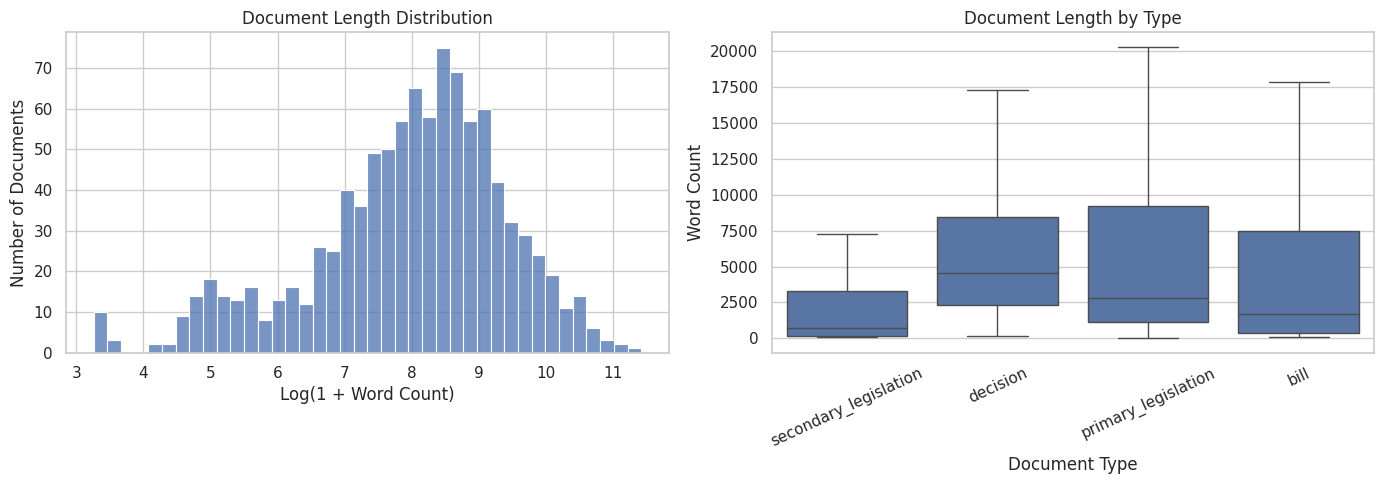

DOCUMENT LENGTH SUMMARY


,word_count
count,1000.000000
mean,6370.850000
std,8846.274677
min,25.000000
25%,1335.500000
50%,3526.500000
75%,7649.000000
max,91018.000000



MEDIAN WORD COUNT BY DOCUMENT TYPE


,word_count
type,
decision,4530.5
primary_legislation,2827.0
bill,1723.0
secondary_legislation,690.5


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(
    np.log1p(df["word_count"]),
    bins=40,
    ax=axes[0]
)
axes[0].set_title("Document Length Distribution")
axes[0].set_xlabel("Log(1 + Word Count)")
axes[0].set_ylabel("Number of Documents")
sns.boxplot(
    data=df,
    x="type",
    y="word_count",
    ax=axes[1],
    showfliers=False
)
axes[1].set_title("Document Length by Type")
axes[1].set_xlabel("Document Type")
axes[1].set_ylabel("Word Count")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()
print("DOCUMENT LENGTH SUMMARY")
display(df["word_count"].describe())
print("\nMEDIAN WORD COUNT BY DOCUMENT TYPE")
display(
    df.groupby("type")["word_count"]
    .median()
    .sort_values(ascending=False)
)



## 6. Document Length Analysis

### Visualizations

A histogram of log-transformed word counts and a
boxplot comparing document lengths across legal
document types were generated.

### Key Findings

Document lengths vary substantially across the corpus.

- Minimum length: 25 words
- Median length: 3,526.5 words
- Maximum length: 91,018 words
- Mean length: 6,370.85 words

The distribution is strongly right-skewed, with
a relatively small number of extremely long documents.

Median document lengths differ by type:

- Decisions: 4,530.5 words
- Primary legislation: 2,827 words
- Bills: 1,723 words
- Secondary legislation: 690.5 words

### Implications for LexiAssist

The variation in document lengths highlights the
importance of an appropriate chunking strategy.

Long legal documents will need to be divided into
smaller, context-preserving chunks for effective
retrieval.

Short documents may require fewer chunks or no
splitting at all.

Document boundaries, legal citations, and section
references should be preserved during chunking.


## 7. Missing Metadata Analysis

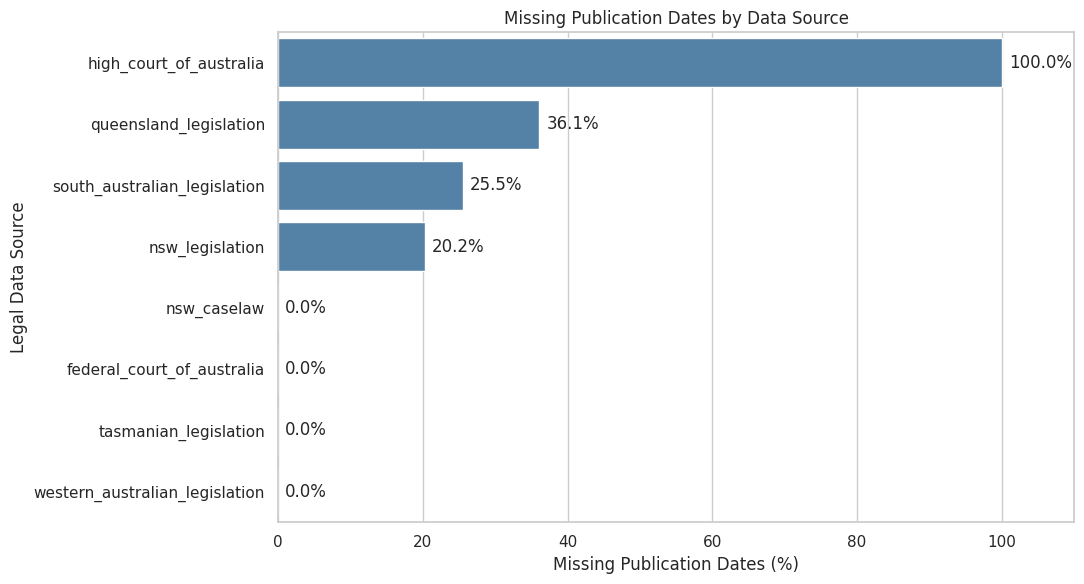

MISSING DATES BY SOURCE


,Missing Dates,Total Documents,Missing Rate
source,,,
high_court_of_australia,55,55,1.000000
queensland_legislation,22,61,0.360656
nsw_legislation,17,84,0.202381
south_australian_legislation,13,51,0.254902
nsw_caselaw,0,283,0.000000
federal_court_of_australia,0,278,0.000000
tasmanian_legislation,0,114,0.000000
western_australian_legislation,0,74,0.000000


Total missing dates: 107


In [ ]:
missing_by_source = (
    df.groupby("source")["date"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)
plt.figure(figsize=(11, 6))
ax = sns.barplot(
    x=missing_by_source.values,
    y=missing_by_source.index,
    color="steelblue"
)
plt.title("Missing Publication Dates by Data Source")
plt.xlabel("Missing Publication Dates (%)")
plt.ylabel("Legal Data Source")
for i, percentage in enumerate(missing_by_source.values):
    ax.text(
        percentage + 1,
        i,
        f"{percentage:.1f}%",
        va="center"
    )

plt.xlim(0, 110)
plt.tight_layout()
plt.show()
print("MISSING DATES BY SOURCE")
display(
    df.assign(date_missing=df["date"].isna())
    .groupby("source")["date_missing"]
    .agg(["sum", "count", "mean"])
    .rename(columns={
        "sum": "Missing Dates",
        "count": "Total Documents",
        "mean": "Missing Rate"
    })
    .sort_values("Missing Dates", ascending=False)
)
print("Total missing dates:", df["date"].isna().sum())


## Missing Metadata Analysis

### Key Findings

107 documents (10.7%) have missing publication dates.

Missing dates are concentrated in four sources:
- High Court of Australia: 55 (100%)
- Queensland Legislation: 22 (36.1%)
- NSW Legislation: 17 (20.2%)
- South Australian Legislation: 13 (25.5%)

### Implications for LexiAssist

Missing publication dates can limit date-based filtering
and affect time-sensitive legal research.

These documents were retained to preserve valuable
legal information. Missing dates must not be replaced
with invented values.



## 8. Jurisdiction vs Document Type


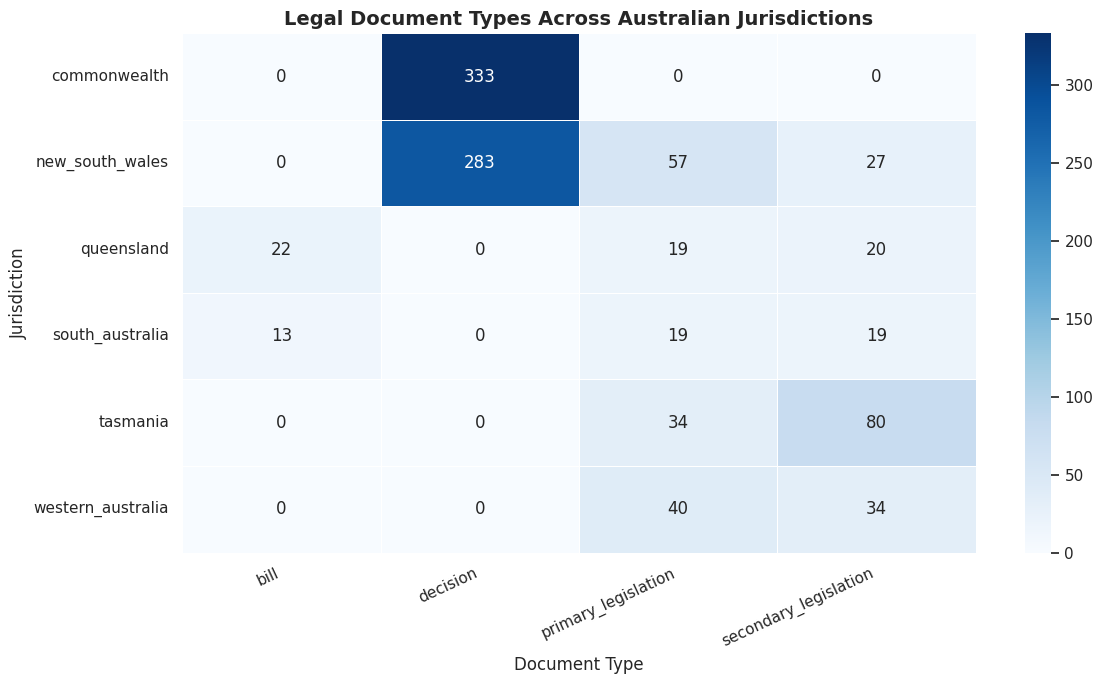

DOCUMENT TYPE COUNTS BY JURISDICTION


type,bill,decision,primary_legislation,secondary_legislation
jurisdiction,,,,
commonwealth,0,333,0,0
new_south_wales,0,283,57,27
queensland,22,0,19,20
south_australia,13,0,19,19
tasmania,0,0,34,80
western_australia,0,0,40,34



PERCENTAGE DISTRIBUTION


type,bill,decision,primary_legislation,secondary_legislation
jurisdiction,,,,
commonwealth,0.00,100.00,0.00,0.00
new_south_wales,0.00,77.11,15.53,7.36
queensland,36.07,0.00,31.15,32.79
south_australia,25.49,0.00,37.25,37.25
tasmania,0.00,0.00,29.82,70.18
western_australia,0.00,0.00,54.05,45.95


In [ ]:

jurisdiction_type = pd.crosstab(
    df["jurisdiction"],
    df["type"]
)
plt.figure(figsize=(12, 7))
sns.heatmap(
    jurisdiction_type,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)
plt.title(
    "Legal Document Types Across Australian Jurisdictions",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Document Type")
plt.ylabel("Jurisdiction")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
print("DOCUMENT TYPE COUNTS BY JURISDICTION")
display(jurisdiction_type)
jurisdiction_type_pct = (
    pd.crosstab(
        df["jurisdiction"],
        df["type"],
        normalize="index"
    ) * 100
).round(2)
print("\nPERCENTAGE DISTRIBUTION")
display(jurisdiction_type_pct)



### Key Findings

The heatmap reveals substantial differences in
document-type representation across jurisdictions.

- Commonwealth: All 333 sampled documents are decisions.
- New South Wales: Decisions dominate, representing
  77.11% of its documents.
- Tasmania: Secondary legislation represents 70.18%
  of its documents.
- Western Australia: Primary legislation accounts
  for 54.05% of its documents.
- Queensland and South Australia: Both contain bills,
  primary legislation, and secondary legislation,
  but no decisions in this sample.

These patterns reflect the composition of the
sampled corpus and its contributing data sources,
not the complete legal systems of these jurisdictions.

### Implications for LexiAssist

The strong relationship between jurisdiction and
document type may influence retrieval behavior.

For example, a query requesting Commonwealth
legislation may have limited coverage in this sample
because Commonwealth legislation is not represented.

Retrieval evaluation should therefore consider
both jurisdiction and document type.

This will help identify corpus coverage limitations
and distinguish retrieval failures from missing
source material.



## 9. Final EDA Summary and Key Insights

Exploratory Data Analysis was performed on 1,000
cleaned documents from the Open Australian Legal Corpus.

### Key Findings

1. **Document Type Imbalance:**
   Decisions account for 61.6% of the corpus.

2. **Jurisdiction Imbalance:**
   New South Wales and Commonwealth together
   account for 70% of the documents.

3. **Source Concentration:**
   NSW Caselaw and the Federal Court of Australia
   contribute 56.1% of the sample.

4. **Publication Dates:**
   Documents range from 1929 to 2024, with
   107 missing publication dates.

5. **Document Length Variation:**
   Word counts range from 25 to 91,018,
   with a median of 3,526.5 words.

6. **Missing Metadata:**
   Missing dates are concentrated in specific
   data sources, particularly the High Court
   of Australia.

7. **Jurisdiction-Type Relationships:**
   Document types are unevenly distributed
   across jurisdictions.

### Implications for LexiAssist

The findings suggest several important
considerations for the RAG system:

- Use context-preserving chunking for long documents.
- Preserve jurisdiction, source, and citation metadata.
- Evaluate retrieval across different document types.
- Consider jurisdiction-specific coverage gaps.
- Handle missing publication dates explicitly.
- Avoid assuming the sampled corpus represents
  the complete or current state of Australian law.

### Conclusion

The EDA process identified important distributions,
data-quality limitations, and corpus characteristics.

These insights will guide text preprocessing,
document chunking, retrieval design, and evaluation
in subsequent project phases.
